### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# Fig. 1B–D, Fig. S1A–C, Fig. S2A — SLC transporter dysregulation across the ALD spectrum (InTEAM cohort)

##### Author: Inês

Fig. S2A shows only the InTEAM per-sample SLC38A4 expression panel. Panels S2B/C of the same supplementary figure come from an independent single-cell RNA-seq analysis (Hannah) and are not part of this notebook.


In [2]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import re
import os
import scipy
from scipy.stats import spearmanr
import warnings
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')


In [3]:
# ============================================================
# Global plot settings
# ============================================================

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':         10,
    'pdf.fonttype':      42,
    'ps.fonttype':       42
})

In [4]:
# ============================================================
# Output directories
# ============================================================

# Outputs are written flat into this folder, alongside the notebook (see repo README).

In [5]:
# ============================================================
# Global constants
# ============================================================

ALPHA      = 0.05
COMP_ORDER = [
    "Early_ALD_vs_Normal",
    "SAH_vs_Normal",
    "SAH_vs_Early_ALD",
    "ExSAH_vs_SAH"
]
STAGE_ORDER = ["Normal", "Early", "SAH", "ExSAH"]

---
## Section 1: Load ReSOLUTE SLC Gene Annotation

In [6]:
# ============================================================
# LOAD ReSOLUTE SLC GENE ANNOTATION
# ============================================================
file_path = 'ReSOLUTE_SLC_ 464_genes_annotation.xlsx'

slc = pd.read_excel(
    file_path,
    sheet_name=None,
    engine="openpyxl",
    header=[0, 1]
)
print("Sheets:", slc.keys())

slc_hgnc_symbol = slc['dataset'].xs('HGNC symbol', axis=1, level=1)
print(f"Unique SLC genes in ReSOLUTE: {slc_hgnc_symbol.nunique().values[0]}")

slc_genes = (
    slc_hgnc_symbol
    .squeeze()
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
    .unique()
)
print(f"SLC gene list length: {len(slc_genes)}")
print("First 10:", slc_genes[:10])

Sheets: dict_keys(['dataset'])
Unique SLC genes in ReSOLUTE: 464
SLC gene list length: 464
First 10: ['SLC1A1' 'SLC1A2' 'SLC1A3' 'SLC1A4' 'SLC1A5' 'SLC1A6' 'SLC1A7' 'SLC2A1'
 'SLC2A2' 'SLC2A3']


---
## Section 2: Load and Clean InTEAM RNA-seq Data

In [7]:
# ============================================================
# LOAD InTEAM RNA-seq DESEQ2 RESULTS
# ============================================================
file_path = "inteam_res_complete_20251023.xlsx"

dfs = pd.read_excel(file_path, sheet_name=None, engine="openpyxl")
print("Available comparisons:", list(dfs.keys()))

# Map raw sheet names (as stored in the source Excel file) onto the
# disease-stage terminology used in the manuscript and figure legends
# (SAH / ExSAH rather than AH / ExAH). Applied once here so every
# downstream pivot table, filter and figure uses consistent naming.
RAW_TO_DISPLAY_COMPARISON = {
    "Early_ALD_vs_normal":  "Early_ALD_vs_Normal",
    "AH_vs_normal":         "SAH_vs_Normal",
    "AH_vs_Early_ALD":      "SAH_vs_Early_ALD",
    "ExAH_vs_AH":           "ExSAH_vs_SAH",
    "AH_vs_HCV_infected":   "SAH_vs_HCV_infected",
    "AH_vs_NAFLD":          "SAH_vs_NAFLD",
    "AH_vs_HCV_cirrhosis":  "SAH_vs_HCV_cirrhosis",
}

# Clean and standardise each sheet
cleaned_df = []
for comp_name, df in dfs.items():
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "")
    )
    df = df.rename(columns={
        "log2foldchange": "log2fc",
        "basemean":       "basemean",
        "padj":           "padj",
        "pvalue":         "pvalue",
        "symbol":         "gene"
    })
    df["comparison"] = RAW_TO_DISPLAY_COMPARISON.get(comp_name, comp_name)
    cleaned_df.append(df)

combined_df = pd.concat(cleaned_df, ignore_index=True)
print(f"\nCombined shape: {combined_df.shape}")
print(combined_df["comparison"].value_counts())

Available comparisons: ['AH_vs_normal', 'Early_ALD_vs_normal', 'AH_vs_Early_ALD', 'ExAH_vs_AH', 'AH_vs_HCV_infected', 'AH_vs_NAFLD', 'AH_vs_HCV_cirrhosis']

Combined shape: (286237, 8)
comparison
SAH_vs_Normal           40891
Early_ALD_vs_Normal     40891
SAH_vs_Early_ALD        40891
ExSAH_vs_SAH            40891
SAH_vs_HCV_infected     40891
SAH_vs_NAFLD            40891
SAH_vs_HCV_cirrhosis    40891
Name: count, dtype: int64


In [8]:
# ============================================================
# FILTER: KEEP ONLY DISEASE PROGRESSION COMPARISONS
# ============================================================
drop = ["SAH_vs_HCV_infected", "SAH_vs_NAFLD", "SAH_vs_HCV_cirrhosis"]
filtered_df = combined_df[~combined_df["comparison"].isin(drop)].copy()

print("Retained comparisons:")
print(filtered_df["comparison"].value_counts())
print(f"\nRows with missing gene symbol: {filtered_df['gene'].isna().sum()}")

# ============================================================
# FILTER: KEEP ONLY SLC GENES
# ============================================================
slc_df = filtered_df[filtered_df["gene"].isin(slc_genes)].copy()

# Enforce comparison order as categorical
slc_df["comparison"] = pd.Categorical(
    slc_df["comparison"],
    categories=COMP_ORDER,
    ordered=True
)
slc_df = slc_df.sort_values("comparison")

print(f"\nSLC rows:     {len(slc_df)}")
print(f"Unique genes: {slc_df['gene'].nunique()}")

Retained comparisons:
comparison
SAH_vs_Normal          40891
Early_ALD_vs_Normal    40891
SAH_vs_Early_ALD       40891
ExSAH_vs_SAH           40891
Name: count, dtype: int64

Rows with missing gene symbol: 55712

SLC rows:     1832
Unique genes: 456


In [9]:
# ============================================================
# IDENTIFY SLC GENES NOT DETECTED IN DATASET
# ============================================================
detected_slc_genes  = set(slc_df["gene"].dropna().str.strip().str.upper().unique())
reference_slc_genes = set(slc_genes)
missing_slc_genes   = reference_slc_genes - detected_slc_genes

print(f"Total annotated SLC genes (ReSOLUTE): {len(reference_slc_genes)}")
print(f"SLC genes detected in RNA-seq:        {len(detected_slc_genes)}")
print(f"SLC genes NOT detected:               {len(missing_slc_genes)}")
print("\nMissing genes:")
for g in sorted(missing_slc_genes):
    print(f"  {g}")

# Verified: these 8 genes are absent from the entire InTEAM dataset
# for biologically consistent reasons (pseudogenes, tissue-restricted expression)

Total annotated SLC genes (ReSOLUTE): 464
SLC genes detected in RNA-seq:        456
SLC genes NOT detected:               8

Missing genes:
  MPC1L
  SLC18A3
  SLC23A4P
  SLC35E2A
  SLC35G4
  SLC66A1LP
  SLC6A21P
  SLCO1B7


---
## Section 3: Build Pivot Tables
These are the core data structures used throughout all analyses.
**Important:** `pivot_fc` and `pivot_padj` use original comparison names as columns.
The Table section creates separate renamed versions (`supp_df`) — 
these are kept strictly separate to avoid overwriting shared variables.

In [10]:
# ============================================================
# BUILD CORE PIVOT TABLES
# NOTE: These use original comparison names as column headers.
# Do NOT rename these columns — they are used throughout the notebook.
# ============================================================

pivot_fc = slc_df.pivot_table(
    index="gene",
    columns="comparison",
    values="log2fc"
)

pivot_padj = slc_df.pivot_table(
    index="gene",
    columns="comparison",
    values="padj"
)

# Combined pivot (log2fc + padj) — used for progressive gene analysis
pivot_df = pivot_fc.join(pivot_padj, rsuffix="_padj")

print(f"pivot_fc shape:   {pivot_fc.shape}")
print(f"pivot_padj shape: {pivot_padj.shape}")
print(f"pivot_df shape:   {pivot_df.shape}")
print("\nColumn names in pivot_fc:")
print(list(pivot_fc.columns))

# Quick check: SLC38A4
print("\nSLC38A4 log2FC values:")
print(pivot_fc.loc["SLC38A4"])

pivot_fc shape:   (456, 4)
pivot_padj shape: (440, 4)
pivot_df shape:   (456, 8)

Column names in pivot_fc:
['Early_ALD_vs_Normal', 'SAH_vs_Normal', 'SAH_vs_Early_ALD', 'ExSAH_vs_SAH']

SLC38A4 log2FC values:
comparison
Early_ALD_vs_Normal    0.054546
SAH_vs_Normal         -2.349769
SAH_vs_Early_ALD      -2.404315
ExSAH_vs_SAH          -0.607067
Name: SLC38A4, dtype: float64


In [11]:
# ============================================================
# COUNT SIGNIFICANT SLC GENES PER COMPARISON
# ============================================================
total_slc = slc_df["gene"].nunique()

sig_counts = (
    slc_df.assign(significant=slc_df["padj"] < ALPHA)
    .groupby("comparison")["significant"]
    .sum()
)

print("Significant SLC genes (FDR < 0.05) per comparison:")
for comp, count in sig_counts.items():
    pct = (count / total_slc) * 100
    print(f"  {comp:<30} {int(count):>3}  ({pct:.1f}%)")

Significant SLC genes (FDR < 0.05) per comparison:
  Early_ALD_vs_Normal            152  (33.3%)
  SAH_vs_Normal                  276  (60.5%)
  SAH_vs_Early_ALD               253  (55.5%)
  ExSAH_vs_SAH                   155  (34.0%)


---
## Section 4: Figure 1B — Violin Plot of SLC Gene Expression Changes

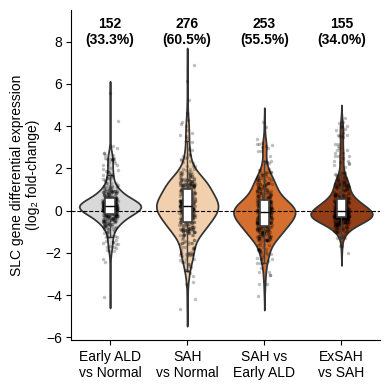

✅ Figure 1B saved


In [12]:
# ============================================================
# FIGURE 1B — Violin plot of SLC gene differential expression
# Shows the distribution of log2 fold-changes for all detected
# SLC transporter genes across four pairwise comparisons.
# Numbers above each violin = n significant (FDR < 0.05).
# ============================================================

comp_order = [
    "Early_ALD_vs_Normal",
    "SAH_vs_Normal",
    "SAH_vs_Early_ALD",
    "ExSAH_vs_SAH"
]

x_labels = [
    "Early ALD\nvs Normal",
    "SAH\nvs Normal",
    "SAH vs\nEarly ALD",
    "ExSAH\nvs SAH"
]

palette = ["#d9d9d9", "#fdd0a2", "#f16913", "#a63603"]

total_slc = slc_df["gene"].nunique()

sig_counts = (
    slc_df.assign(significant=slc_df["padj"] < ALPHA)
    .groupby("comparison")["significant"]
    .sum()
)

fig, ax = plt.subplots(figsize=(4, 4))

sns.violinplot(
    data=slc_df,
    x="comparison", y="log2fc",
    hue="comparison",
    inner=None,
    palette=palette,
    order=comp_order,
    dodge=False,
    legend=False,
    ax=ax
)

sns.boxplot(
    data=slc_df,
    x="comparison", y="log2fc",
    width=0.12,
    showcaps=True,
    boxprops={"facecolor": "white", "linewidth": 1.2, "zorder": 5},
    whiskerprops={"linewidth": 1, "zorder": 6},
    medianprops={"color": "black", "linewidth": 1, "zorder": 6},
    showfliers=False,
    order=comp_order,
    ax=ax
)

sns.stripplot(
    data=slc_df,
    x="comparison", y="log2fc",
    color="black",
    size=2.5,
    alpha=0.25,
    jitter=True,
    zorder=3,
    order=comp_order,
    ax=ax
)

ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_ylim(None, 9.5)

y_max = slc_df["log2fc"].max()
for i, comp in enumerate(comp_order):
    count = int(sig_counts.get(comp, 0))
    pct   = (count / total_slc) * 100
    ax.text(i, y_max + 1, f"{count}\n({pct:.1f}%)",
            ha="center", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(comp_order)))
ax.set_xticklabels(x_labels, fontsize=10)
ax.set_xlabel("")
ax.set_ylabel("SLC gene differential expression\n(log\u2082 fold-change)", fontsize=10)
sns.despine(ax=ax)
plt.tight_layout()

plt.savefig("Fig1B_SLC_violin_plot.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("\u2705 Figure 1B saved")


---
## Section 5: Identify Progressively Dysregulated SLC Genes
### 5a: Relaxed filter (direction-based) — used for Supplementary Figure 1C trajectory plots
### 5b: Stringent filter (three-step) — used for Figure 1C heatmap

In [13]:
# ============================================================
# PROGRESSIVE GENE ANALYSIS
# Two filtering strategies are used:
#
# (A) RELAXED — direction-based, FDR < 0.05 in >= 2 comparisons
#     → Used for Supplementary Figure 1C trajectory plots
#     → Yields: progressive_sig_genes (115 down, 92 up)
#
# (B) STRINGENT — three-step filter
#     → Used for Figure 1C heatmap
#     → Yields: heatmap_data (14 genes)
# ============================================================

# -----------------------------------------------------------
# (A) RELAXED FILTER — progressive_sig_genes
# -----------------------------------------------------------
def is_progressive_late(row):
    step1 = row.get("SAH_vs_Early_ALD")
    step2 = row.get("ExSAH_vs_SAH")
    vals  = [v for v in [step1, step2] if pd.notna(v)]
    if len(vals) < 2:
        return False
    return (step1 > 0 and step2 > 0) or (step1 < 0 and step2 < 0)

pivot_df["progressive"] = pivot_df.apply(is_progressive_late, axis=1)

sig_pivot  = slc_df.pivot_table(index="gene", columns="comparison",
                                 values="padj", aggfunc="min")
sig_filter = (sig_pivot < ALPHA).sum(axis=1) >= 2

progressive_sig_genes = pivot_df[pivot_df["progressive"] & sig_filter].copy()

def get_direction(row):
    if   row["SAH_vs_Early_ALD"] > 0: return "Up"
    elif row["SAH_vs_Early_ALD"] < 0: return "Down"
    else:                              return "Neutral"

progressive_sig_genes = progressive_sig_genes.copy()
progressive_sig_genes["direction"] = progressive_sig_genes.apply(
    get_direction, axis=1
)

print("(A) Relaxed filter — progressive_sig_genes:")
print(progressive_sig_genes["direction"].value_counts())

# -----------------------------------------------------------
# (B) STRINGENT FILTER — three-step, for Figure 1C heatmap
# -----------------------------------------------------------
pivot_log2fc = pivot_df[COMP_ORDER].copy().apply(pd.to_numeric, errors="coerce")
pivot_padj_f = pivot_df[[f"{c}_padj" for c in COMP_ORDER]].copy()
pivot_padj_f.columns = COMP_ORDER  # rename to match log2fc for easy indexing
pivot_padj_f = pivot_padj_f.apply(pd.to_numeric, errors="coerce")

# Step 1 — Stable in Early ALD vs Normal
stable_early = (
    (pivot_log2fc["Early_ALD_vs_Normal"].abs() < 0.25) &
    (pivot_padj_f["Early_ALD_vs_Normal"] >= 0.05)
)
# Step 2 — Significantly DE in SAH vs Early ALD (FDR < 0.001, |log2FC| > 1)
sig_ah = (
    (pivot_padj_f["SAH_vs_Early_ALD"] < 0.001) &
    (pivot_log2fc["SAH_vs_Early_ALD"].abs() > 1)
)
# Step 3 — Consistent direction in ExSAH vs SAH
same_direction = (
    ((pivot_log2fc["SAH_vs_Early_ALD"] > 0) & (pivot_log2fc["ExSAH_vs_SAH"] > 0.5)) |
    ((pivot_log2fc["SAH_vs_Early_ALD"] < 0) & (pivot_log2fc["ExSAH_vs_SAH"] < -0.5))
)

progressive_mask  = stable_early & sig_ah & same_direction
progressive_genes = pivot_log2fc[progressive_mask].copy()

print(f"\n(B) Stringent filter — genes passing all three steps: {len(progressive_genes)}")
print(f"  Upregulated:   {(progressive_genes['SAH_vs_Early_ALD'] > 0).sum()}")
print(f"  Downregulated: {(progressive_genes['SAH_vs_Early_ALD'] < 0).sum()}")

# -----------------------------------------------------------
# COMPUTE PROGRESSION SCORE for stringent gene set
# Score = SAH_vs_Early_ALD + ExSAH_vs_SAH log2FC
# More negative = stronger and more sustained downregulation
# -----------------------------------------------------------
progressive_genes["progression_score"] = (
    progressive_genes["SAH_vs_Early_ALD"] +
    progressive_genes["ExSAH_vs_SAH"]
)

print("\nTop 10 most downregulated by progression score:")
print(
    progressive_genes[progressive_genes["SAH_vs_Early_ALD"] < 0]
    ["progression_score"]
    .sort_values(ascending=True)
    .head(10)
)

(A) Relaxed filter — progressive_sig_genes:
direction
Down    115
Up       92
Name: count, dtype: int64

(B) Stringent filter — genes passing all three steps: 14
  Upregulated:   4
  Downregulated: 10

Top 10 most downregulated by progression score:
gene
RHBG      -3.548622
SLC22A1   -3.105885
SLC38A4   -3.011382
SLCO1B3   -2.999625
SLC17A2   -2.943680
SLC10A1   -2.840252
SLCO1B1   -2.375583
SLC10A5   -2.106110
SLC27A2   -2.010837
SLC46A1   -1.797606
Name: progression_score, dtype: float64


---
## Section 6: Figure 1C — Heatmap of Top Progressively Dysregulated SLC Genes

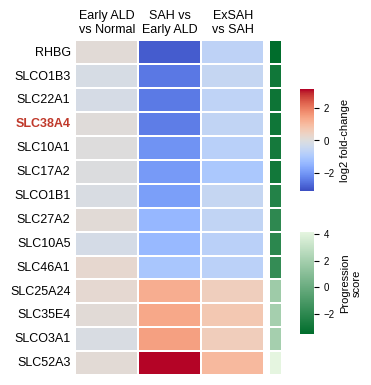

✅ Figure 1C saved


In [14]:
# ============================================================
# FIGURE 1C — Heatmap of progressively dysregulated SLC genes
# Left panel: log2 fold-change heatmap (coolwarm, 3 comparisons)
# Right sidebar: progression score (AH_vs_Early_ALD + ExAH_vs_AH)
# Gene order: most downregulated in SAH vs Early ALD at top.
# SLC38A4 is highlighted in bold red.
# Uses: progressive_genes (stringent three-step filter, 14 genes)
# ============================================================
from matplotlib.colors import LinearSegmentedColormap

cols_to_plot = ["Early_ALD_vs_Normal", "SAH_vs_Early_ALD", "ExSAH_vs_SAH"]
col_labels   = ["Early ALD\nvs Normal", "SAH vs\nEarly ALD", "ExSAH\nvs SAH"]

heatmap_data = (
    progressive_genes[cols_to_plot + ["progression_score"]]
    .dropna(subset=cols_to_plot, thresh=2)
    .sort_values("SAH_vs_Early_ALD", ascending=True)
    .copy()
)

score_data   = heatmap_data[["progression_score"]].copy()
score_values = score_data["progression_score"].values.reshape(-1, 1)
score_vmin   = score_values.min()
score_vmax   = score_values.max()

# Figure layout — 4 axes: main heatmap, score sidebar, two colourbars
fig        = plt.figure(figsize=(4.5, len(heatmap_data) * 0.22 + 1))
ax_heatmap = fig.add_axes([0.25, 0.10, 0.42, 0.82])
ax_score   = fig.add_axes([0.68, 0.10, 0.03, 0.82])
ax_cbar_fc = fig.add_axes([0.75, 0.55, 0.03, 0.25])
ax_cbar_sc = fig.add_axes([0.75, 0.20, 0.03, 0.25])

# Main heatmap (log2 fold-change)
vmax = np.nanmax(np.abs(heatmap_data[cols_to_plot].values))
sns.heatmap(
    heatmap_data[cols_to_plot],
    cmap="coolwarm", center=0, vmin=-vmax, vmax=vmax,
    linewidths=0.3, linecolor="white",
    cbar_ax=ax_cbar_fc,
    cbar_kws={"label": "log2 fold-change"},
    yticklabels=True, ax=ax_heatmap
)

# Progression score sidebar — dark green (most negative) to light green
green_cmap = LinearSegmentedColormap.from_list(
    "green_gradient", ["#006d2c", "#e5f5e0"]
)
# Use sns.heatmap so linewidths=0.3 draws white borders between each gene row,
# matching the main heatmap and preserving individual cell boundaries in Illustrator.
sns.heatmap(
    score_data,
    cmap=green_cmap,
    vmin=score_vmin,
    vmax=score_vmax,
    linewidths=0.3, linecolor="white",
    cbar=False,
    ax=ax_score,
    yticklabels=False,
    xticklabels=False,
)
ax_score.set_xlabel("")
ax_score.set_ylabel("")

# Score colourbar — retrieve the QuadMesh from sns.heatmap (pcolormesh-based)
# as the colour-mappable object; avoids the NameError from imshow approach
im = ax_score.collections[0]
cbar_sc = fig.colorbar(im, cax=ax_cbar_sc)
cbar_sc.set_label("Progression\nscore", fontsize=8)
cbar_sc.ax.tick_params(labelsize=7)
cbar_sc.outline.set_visible(False)

# Heatmap axis formatting
ax_heatmap.xaxis.tick_top()
ax_heatmap.xaxis.set_label_position("top")
ax_heatmap.set_xticklabels(col_labels, rotation=0, ha="center", fontsize=9)
ax_heatmap.tick_params(axis="x", length=0)
ax_heatmap.tick_params(axis="y", length=0, labelsize=9)
ax_heatmap.set_xlabel("")
ax_heatmap.set_ylabel("")
for label in ax_heatmap.get_yticklabels():
    if label.get_text() == "SLC38A4":
        label.set_fontweight("bold")
        label.set_color("#c0392b")
for spine in ax_heatmap.spines.values():
    spine.set_visible(False)

ax_cbar_fc.set_ylabel("log2 fold-change", fontsize=8)
ax_cbar_fc.tick_params(labelsize=7)

plt.savefig("Fig1C_progressive_SLC_heatmap.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("\u2705 Figure 1C saved")


---
## Section 7: Figure 1D — Trajectory Plot of Downregulated SLC Genes

  RHBG — included (SAH vs Early ALD FC: -2.888)
  SLCO1B3 — included (SAH vs Early ALD FC: -2.478)
  SLC22A1 — included (SAH vs Early ALD FC: -2.468)
  SLC38A4 — included (SAH vs Early ALD FC: -2.404)
  SLC10A1 — included (SAH vs Early ALD FC: -2.077)

Top 10 by progression score:
gene
RHBG      -3.548622
SLC22A1   -3.105885
SLC38A4   -3.011382
SLCO1B3   -2.999625
SLC17A2   -2.943680
SLC10A1   -2.840252
SLCO1B1   -2.375583
SLC10A5   -2.106110
SLC27A2   -2.010837
SLC46A1   -1.797606
Name: progression_score, dtype: float64


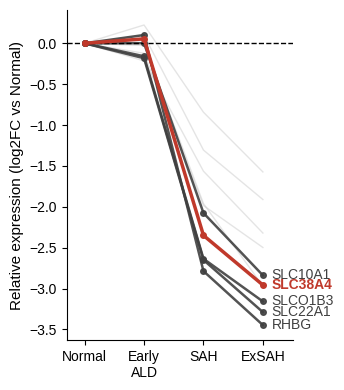

✅ Figure 1D saved


In [15]:
# ============================================================
# FIGURE 1D — Trajectory plot, downregulated genes only
# Uses: heatmap_data (stringent filter, downregulated subset)
# ============================================================
from adjustText import adjust_text

top_genes = ["RHBG", "SLCO1B3", "SLC22A1", "SLC38A4", "SLC10A1"]

downregulated_genes = heatmap_data[heatmap_data["SAH_vs_Early_ALD"] < 0].index

# Build trajectory dataframe
traj_list = []
stage_order_traj = ["Normal", "Early\nALD", "SAH", "ExSAH"]

for gene in downregulated_genes:
    early = pivot_log2fc.loc[gene, "Early_ALD_vs_Normal"]
    ah    = pivot_log2fc.loc[gene, "SAH_vs_Normal"]
    exah  = pivot_log2fc.loc[gene, "SAH_vs_Normal"] + pivot_log2fc.loc[gene, "ExSAH_vs_SAH"]
    traj_list.append(pd.DataFrame({
        "gene":  [gene] * 4,
        "stage": stage_order_traj,
        "value": [0, early, ah, exah]
    }))

traj_df = pd.concat(traj_list, ignore_index=True)
traj_df["stage"] = pd.Categorical(
    traj_df["stage"], categories=stage_order_traj, ordered=True
)

# Confirm top genes
for gene in top_genes:
    if gene in downregulated_genes:
        fc = heatmap_data.loc[gene, "SAH_vs_Early_ALD"]
        print(f"  {gene} — included (SAH vs Early ALD FC: {fc:.3f})")
    else:
        print(f"  {gene} — EXCLUDED")

print("\nTop 10 by progression score:")
print(
    heatmap_data.loc[downregulated_genes, "progression_score"]
    .sort_values(ascending=True)
    .head(10)
)

# --- Plot
fig, ax = plt.subplots(figsize=(3.5, 4))

for gene in traj_df["gene"].unique():
    subset = traj_df[traj_df["gene"] == gene].sort_values("stage")
    is_slc = gene == "SLC38A4"
    is_top = gene in top_genes
    ax.plot(
        subset["stage"], subset["value"],
        color    = "#c0392b" if is_slc else ("#404040" if is_top else "#bdbdbd"),
        linewidth= 2.5 if is_slc else (1.8 if is_top else 1.0),
        alpha    = 1.0 if is_slc else (0.9 if is_top else 0.4),
        marker   = "o" if is_top else None,
        markersize=4 if is_top else None,
        zorder   = 3 if is_slc else (2 if is_top else 1),
        linestyle= "-"
    )

# Labels for top genes
ax.set_xlim(-0.3, 3.5)
texts = []
for gene in top_genes:
    if gene not in downregulated_genes:
        continue
    subset = traj_df[traj_df["gene"] == gene].sort_values("stage")
    if subset.empty or pd.isna(subset["value"].iloc[-1]):
        continue
    y = subset["value"].iloc[-1]
    texts.append(ax.text(
        x=3.15, y=y, s=gene,
        fontsize=10,
        fontweight="bold" if gene == "SLC38A4" else "normal",
        color="#c0392b" if gene == "SLC38A4" else "#404040",
        va="center", ha="left"
    ))

ax.axhline(0, linestyle="--", color="black", linewidth=1)
ax.set_xticks(range(len(stage_order_traj)))
ax.set_xticklabels(stage_order_traj, fontsize=10)
#ax.set_xlabel("Disease stage", fontsize=11)
ax.set_ylabel("Relative expression (log2FC vs Normal)", fontsize=11)
sns.despine(ax=ax)
plt.tight_layout()

plt.savefig("Fig1D_trajectory_downregulated.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("✅ Figure 1D saved")

---
## Section 8: Supplementary Figure 1 — Global Pattern of SLC Differential Expression
### Panel A: Spearman correlation heatmap
### Panel B: Scatter plots (late-emerging signal)
### Panel C: Trajectory plots (progressive up/downregulation)

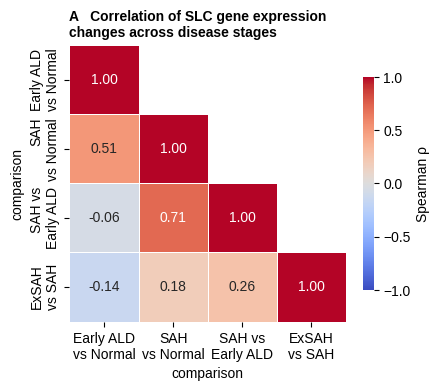

✅ Supplementary Figure 1A saved


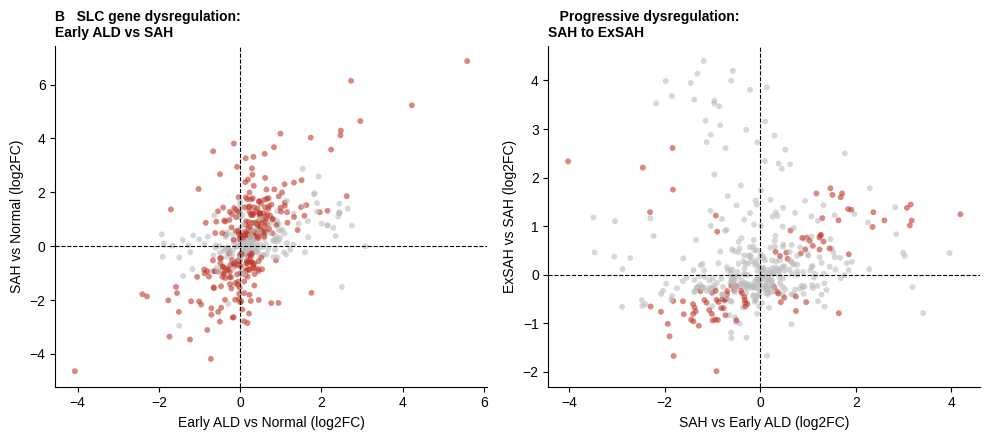

✅ Supplementary Figure 1B saved

Trajectory plot genes: 115 down, 92 up


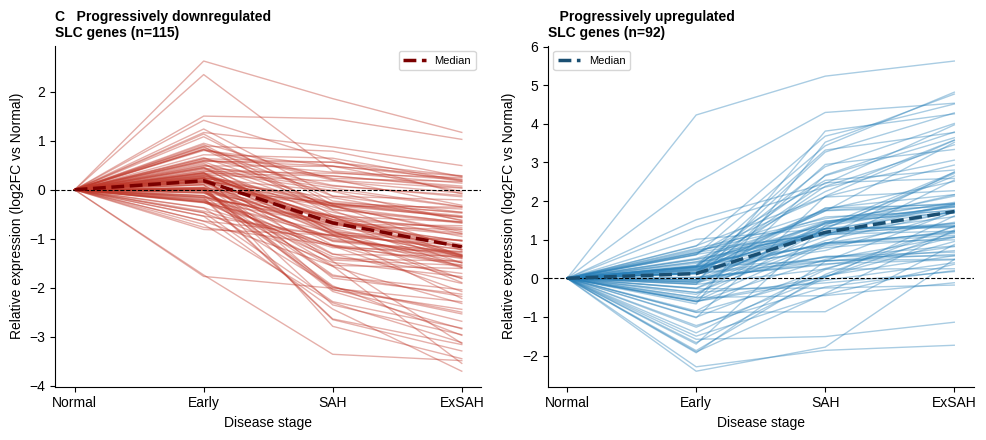

✅ Supplementary Figure 1C saved


In [16]:
# ============================================================
# SUPPLEMENTARY FIGURE 1
# Uses: pivot_fc, pivot_padj, progressive_sig_genes (relaxed filter)
# ============================================================

# -----------------------------------------------------------
# Panel A — Spearman correlation heatmap
# -----------------------------------------------------------
corr_matrix = pivot_fc[COMP_ORDER].corr(method="spearman")

supp_labels = [
    "Early ALD\nvs Normal",
    "SAH\nvs Normal",
    "SAH vs\nEarly ALD",
    "ExSAH\nvs SAH"
]
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1,
    mask=mask, square=True, linewidths=0.5,
    cbar_kws={"label": "Spearman ρ", "shrink": 0.7},
    xticklabels=supp_labels, yticklabels=supp_labels, ax=ax
)
ax.set_title(
    "A   Correlation of SLC gene expression\nchanges across disease stages",
    fontsize=10, loc="left", fontweight="bold"
)
plt.tight_layout()
plt.savefig("FigS1A_correlation_heatmap.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("✅ Supplementary Figure 1A saved")

# -----------------------------------------------------------
# Panel B — Scatter plots: late-emerging signal
# -----------------------------------------------------------
sig_in_ah      = pivot_padj.index[pivot_padj["SAH_vs_Normal"] < ALPHA]
sig_progressive = pivot_padj.index[
    (pivot_padj["SAH_vs_Early_ALD"] < ALPHA) &
    (pivot_padj["ExSAH_vs_SAH"] < ALPHA)
]
colors_ah   = ["#c0392b" if g in sig_in_ah      else "#bdbdbd" for g in pivot_fc.index]
colors_prog = ["#c0392b" if g in sig_progressive else "#bdbdbd" for g in pivot_fc.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.scatter(pivot_fc["Early_ALD_vs_Normal"], pivot_fc["SAH_vs_Normal"],
           c=colors_ah, alpha=0.6, s=18, linewidths=0)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_xlabel("Early ALD vs Normal (log2FC)", fontsize=10)
ax.set_ylabel("SAH vs Normal (log2FC)", fontsize=10)
ax.set_title("B   SLC gene dysregulation:\nEarly ALD vs SAH",
             fontsize=10, loc="left", fontweight="bold")
sns.despine(ax=ax)

ax = axes[1]
ax.scatter(pivot_fc["SAH_vs_Early_ALD"], pivot_fc["ExSAH_vs_SAH"],
           c=colors_prog, alpha=0.6, s=18, linewidths=0)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_xlabel("SAH vs Early ALD (log2FC)", fontsize=10)
ax.set_ylabel("ExSAH vs SAH (log2FC)", fontsize=10)
ax.set_title("   Progressive dysregulation:\nSAH to ExSAH",
             fontsize=10, loc="left", fontweight="bold")
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("FigS1B_scatter_progression.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("✅ Supplementary Figure 1B saved")

# -----------------------------------------------------------
# Panel C — Trajectory plots: progressive up/downregulation
# Uses: progressive_sig_genes (RELAXED filter — 115 down, 92 up)
# -----------------------------------------------------------
down_genes = progressive_sig_genes[
    progressive_sig_genes["SAH_vs_Early_ALD"] < 0
].index.tolist()
up_genes = progressive_sig_genes[
    progressive_sig_genes["SAH_vs_Early_ALD"] > 0
].index.tolist()

n_down = len(down_genes)
n_up   = len(up_genes)
print(f"\nTrajectory plot genes: {n_down} down, {n_up} up")

def build_traj_from_pivot(gene_list, pivot):
    """Build long-format trajectory dataframe relative to Normal (= 0)."""
    traj_list = []
    for gene in gene_list:
        if gene not in pivot.index:
            continue
        row       = pivot.loc[gene]
        early     = row.get("Early_ALD_vs_Normal", np.nan)
        ah        = row.get("SAH_vs_Normal",        np.nan)
        exah_step = row.get("ExSAH_vs_SAH",          np.nan)
        exah      = (ah + exah_step) if pd.notna(ah) and pd.notna(exah_step) \
                    else np.nan
        traj_list.append(pd.DataFrame({
            "gene":  [gene] * 4,
            "stage": STAGE_ORDER,
            "value": [0, early, ah, exah]
        }))
    return pd.concat(traj_list, ignore_index=True)

traj_down = build_traj_from_pivot(down_genes, pivot_fc)
traj_up   = build_traj_from_pivot(up_genes,   pivot_fc)

for traj in [traj_down, traj_up]:
    traj["stage"] = pd.Categorical(
        traj["stage"], categories=STAGE_ORDER, ordered=True
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Left: downregulated
ax = axes[0]
for gene in traj_down["gene"].unique():
    subset = traj_down[traj_down["gene"] == gene].sort_values("stage")
    ax.plot(subset["stage"], subset["value"],
            color="#c0392b", alpha=0.4, linewidth=1.0)
median_down = (traj_down.groupby("stage", observed=True)["value"]
               .median().reindex(STAGE_ORDER))
ax.plot(STAGE_ORDER, median_down.values,
        color="#7b0000", linewidth=2.5, linestyle="--", zorder=5, label="Median")
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_title(f"C   Progressively downregulated\nSLC genes (n={n_down})",
             fontsize=10, loc="left", fontweight="bold")
ax.set_xlabel("Disease stage")
ax.set_ylabel("Relative expression (log2FC vs Normal)")
ax.legend(fontsize=8)
sns.despine(ax=ax)

# Right: upregulated
ax = axes[1]
for gene in traj_up["gene"].unique():
    subset = traj_up[traj_up["gene"] == gene].sort_values("stage")
    ax.plot(subset["stage"], subset["value"],
            color="#2980b9", alpha=0.4, linewidth=1.0)
median_up = (traj_up.groupby("stage", observed=True)["value"]
             .median().reindex(STAGE_ORDER))
ax.plot(STAGE_ORDER, median_up.values,
        color="#1a4f72", linewidth=2.5, linestyle="--", zorder=5, label="Median")
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_title(f"   Progressively upregulated\nSLC genes (n={n_up})",
             fontsize=10, loc="left", fontweight="bold")
ax.set_xlabel("Disease stage")
ax.set_ylabel("Relative expression (log2FC vs Normal)")
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("FigS1C_trajectories.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("✅ Supplementary Figure 1C saved")

---
## Section 9: Table — All SLC Genes with Differential Expression Statistics
**Note:** This section creates `supp_df` with renamed columns (e.g. `Early_ALD_vs_normal_log2FC`).
These renamed pivot tables are LOCAL to this section and do NOT overwrite `pivot_fc` or `pivot_padj`.

In [17]:
# ============================================================
# Table S2 — All 456 SLC genes, full DE results
# Underlies Fig. 1C, Fig. S1A-C, and Fig. S2A.
# NOTE: Creates LOCAL renamed pivot tables (supp_pivot_fc etc.)
# Does NOT overwrite the shared pivot_fc / pivot_padj variables
# Comparison names are already SAH/ExSAH (renamed at load time in
# Section 2), so no display-name remapping is needed here.
# ============================================================
comparisons = COMP_ORDER

# Build local pivot tables with renamed columns for export
supp_pivot_fc   = slc_df.pivot_table(index="gene", columns="comparison", values="log2fc")
supp_pivot_padj = slc_df.pivot_table(index="gene", columns="comparison", values="padj")
supp_pivot_se   = slc_df.pivot_table(index="gene", columns="comparison", values="lfcse")
supp_pivot_stat = slc_df.pivot_table(index="gene", columns="comparison", values="stat")

supp_pivot_fc.columns   = [f"{c}_log2FC" for c in supp_pivot_fc.columns]
supp_pivot_padj.columns = [f"{c}_padj"   for c in supp_pivot_padj.columns]
supp_pivot_se.columns   = [f"{c}_lfcSE"  for c in supp_pivot_se.columns]
supp_pivot_stat.columns = [f"{c}_stat"   for c in supp_pivot_stat.columns]

supp_df = (
    supp_pivot_fc
    .join(supp_pivot_padj)
    .join(supp_pivot_se)
    .join(supp_pivot_stat)
)

# Ensure numeric
for col in [c for c in supp_df.columns if c.endswith(("_padj", "_log2FC"))]:
    supp_df[col] = pd.to_numeric(supp_df[col], errors="coerce")

# Progression score
supp_df["progression_score"] = (
    supp_df["SAH_vs_Early_ALD_log2FC"] +
    supp_df["ExSAH_vs_SAH_log2FC"]
).round(3)

# Filter flag columns
supp_df["filter1_FC_lt_0.25"]          = (supp_df["Early_ALD_vs_Normal_log2FC"].abs() < 0.25).map({True: "Yes", False: "No"})
supp_df["filter1_padj_ns"]             = (supp_df["Early_ALD_vs_Normal_padj"] >= 0.05).map({True: "Yes", False: "No"})
supp_df["filter2_padj_lt_0.001"]       = (supp_df["SAH_vs_Early_ALD_padj"] < 0.001).map({True: "Yes", False: "No"})
supp_df["filter2_FC_gt_1"]             = (supp_df["SAH_vs_Early_ALD_log2FC"].abs() > 1).map({True: "Yes", False: "No"})
supp_df["filter3_consistent_direction"]= (
    ((supp_df["SAH_vs_Early_ALD_log2FC"] > 0) & (supp_df["ExSAH_vs_SAH_log2FC"] > 0)) |
    ((supp_df["SAH_vs_Early_ALD_log2FC"] < 0) & (supp_df["ExSAH_vs_SAH_log2FC"] < 0))
).map({True: "Yes", False: "No"})
supp_df["passes_all_filters"] = (
    (supp_df["filter1_FC_lt_0.25"]           == "Yes") &
    (supp_df["filter1_padj_ns"]              == "Yes") &
    (supp_df["filter2_padj_lt_0.001"]        == "Yes") &
    (supp_df["filter2_FC_gt_1"]              == "Yes") &
    (supp_df["filter3_consistent_direction"] == "Yes")
).map({True: "Yes", False: "No"})

# Sort and order columns
supp_df = supp_df.sort_values("progression_score", ascending=True, na_position="last")

filter_cols  = ["filter1_FC_lt_0.25", "filter1_padj_ns",
                "filter2_padj_lt_0.001", "filter2_FC_gt_1",
                "filter3_consistent_direction", "passes_all_filters"]
ordered_cols = []
for comp in comparisons:
    ordered_cols.extend([f"{comp}_log2FC", f"{comp}_padj",
                         f"{comp}_lfcSE",  f"{comp}_stat"])
ordered_cols += ["progression_score"] + filter_cols
supp_df = supp_df[ordered_cols]

# Format
for col in [c for c in supp_df.columns if c.endswith(("_log2FC", "_lfcSE"))]:
    supp_df[col] = pd.to_numeric(supp_df[col], errors="coerce").round(3)
for col in [c for c in supp_df.columns if c.endswith("_stat")]:
    supp_df[col] = pd.to_numeric(supp_df[col], errors="coerce").round(2)
for col in [c for c in supp_df.columns if c.endswith("_padj")]:
    supp_df[col] = supp_df[col].apply(lambda x: f"{x:.2e}" if pd.notna(x) else "")

# Export
output_file = "Table_S2_SLC_progression_score.xlsx"
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    supp_df.to_excel(writer, sheet_name="Table_S2", startrow=4)
    ws = writer.sheets["Table_S2"]
    ws["A1"] = "Table S2. Differential expression results for all 456 detected SLC transporter genes across the alcohol-related liver disease spectrum (InTEAM cohort)"
    ws["A2"] = "Includes log2 fold-change, adjusted p-value, standard error and Wald statistic for each of the four pairwise disease-stage comparisons"
    ws["A3"] = "Progression score = sum of SAH_vs_Early_ALD + ExSAH_vs_SAH log2FC; genes are ranked by this score"
    ws["A4"] = "Filter columns indicate whether each gene passes each criterion of the three-step filter used to identify the progressively dysregulated genes shown in Fig. 1C, Fig. S1 and Fig. S2A"
    ws.freeze_panes = "A6"
    for col in ws.columns:
        max_length = max((len(str(cell.value)) for cell in col if cell.value is not None), default=10)
        ws.column_dimensions[col[0].column_letter].width = max_length + 2

print(f"✅ Table S2 saved: {output_file}")
display(supp_df.head(10))

✅ Table S2 saved: Table_S2_SLC_progression_score.xlsx


,Early_ALD_vs_Normal_log2FC,Early_ALD_vs_Normal_padj,Early_ALD_vs_Normal_lfcSE,Early_ALD_vs_Normal_stat,SAH_vs_Normal_log2FC,SAH_vs_Normal_padj,SAH_vs_Normal_lfcSE,SAH_vs_Normal_stat,SAH_vs_Early_ALD_log2FC,SAH_vs_Early_ALD_padj,...,ExSAH_vs_SAH_padj,ExSAH_vs_SAH_lfcSE,ExSAH_vs_SAH_stat,progression_score,filter1_FC_lt_0.25,filter1_padj_ns,filter2_padj_lt_0.001,filter2_FC_gt_1,filter3_consistent_direction,passes_all_filters
gene,,,,,,,,,,,,,,,,,,,,,
RHBG,0.102,9.31e-01,0.590,0.17,-2.787,2.03e-06,0.548,-5.09,-2.888,3.19e-07,...,3.87e-01,0.548,-1.21,-3.549,Yes,Yes,Yes,Yes,Yes,Yes
SLC22A25,0.351,3.63e-01,0.263,1.33,-1.460,1.28e-08,0.242,-6.03,-1.811,9.56e-14,...,3.43e-10,0.237,-7.05,-3.484,No,Yes,Yes,Yes,Yes,No
SLC6A13,-0.539,2.69e-01,0.344,-1.57,-2.435,2.61e-13,0.318,-7.67,-1.895,5.92e-09,...,1.04e-03,0.318,-3.99,-3.163,No,Yes,Yes,Yes,Yes,No
SLC22A1,-0.183,7.42e-01,0.321,-0.57,-2.650,8.87e-18,0.296,-8.95,-2.468,7.06e-17,...,9.04e-02,0.288,-2.22,-3.106,Yes,Yes,Yes,Yes,Yes,Yes
SLC38A4,0.055,9.21e-01,0.279,0.20,-2.350,1.76e-18,0.257,-9.14,-2.404,5.21e-21,...,6.11e-02,0.250,-2.43,-3.011,Yes,Yes,Yes,Yes,Yes,Yes
SLC22A10,-0.719,2.27e-01,0.426,-1.69,-4.184,1.28e-24,0.394,-10.62,-3.465,1.16e-18,...,3.92e-01,0.384,1.19,-3.006,No,Yes,Yes,Yes,No,No
SLCO1B3,-0.158,8.16e-01,0.373,-0.42,-2.636,2.86e-13,0.344,-7.65,-2.478,8.68e-13,...,2.53e-01,0.336,-1.55,-3.000,Yes,Yes,Yes,Yes,Yes,Yes
SLC6A1,0.262,5.26e-01,0.265,0.99,-2.031,1.70e-15,0.244,-8.32,-2.293,3.67e-21,...,3.18e-02,0.238,-2.75,-2.946,No,Yes,Yes,Yes,Yes,No
SLC17A2,-0.027,9.52e-01,0.212,-0.13,-1.961,5.60e-22,0.196,-10.01,-1.934,4.84e-23,...,8.10e-06,0.193,-5.23,-2.944,Yes,Yes,Yes,Yes,Yes,Yes


---
## Section 10: Exploratory / QC Analyses
### Check consistency of SLC gene regulation across disease stages

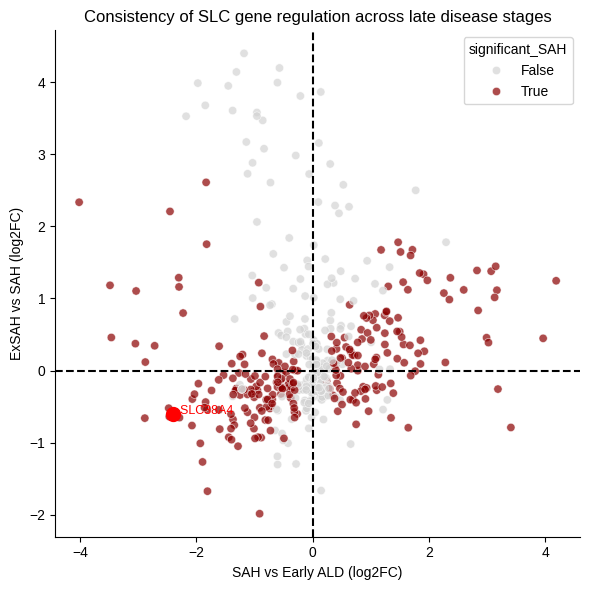

✅ QC scatter plot complete


In [18]:
# ============================================================
# QC — Consistency scatter: SAH_vs_Early_ALD vs ExSAH_vs_SAH
# Uses: pivot_df (original column names)
# ============================================================
pivot_df["significant_SAH"] = pivot_df["SAH_vs_Early_ALD_padj"] < ALPHA

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=pivot_df,
    x="SAH_vs_Early_ALD", y="ExSAH_vs_SAH",
    hue="significant_SAH",
    palette={True: "darkred", False: "lightgrey"},
    alpha=0.7, ax=ax
)
if "SLC38A4" in pivot_df.index:
    x = pivot_df.loc["SLC38A4", "SAH_vs_Early_ALD"]
    y = pivot_df.loc["SLC38A4", "ExSAH_vs_SAH"]
    ax.scatter(x, y, color="red", s=100, zorder=5)
    ax.text(x, y, "  SLC38A4", color="red", fontsize=9)

ax.axhline(0, linestyle="--", color="black")
ax.axvline(0, linestyle="--", color="black")
ax.set_xlabel("SAH vs Early ALD (log2FC)")
ax.set_ylabel("ExSAH vs SAH (log2FC)")
ax.set_title("Consistency of SLC gene regulation across late disease stages")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
print("✅ QC scatter plot complete")

---
## Section 11: Supplementary Figure 2A — SLC38A4 Expression in InTEAM Participants

Individual-level SLC38A4 expression across the ALD disease spectrum
(Normal → Early ALD → SAH → ExSAH) in the InTEAM cohort.
Requires normalised per-sample count data (`df_inteam`) in long format
with columns: `group_label` (str) and `value` (float).
Statistical comparisons use Mann-Whitney U with Bonferroni correction.


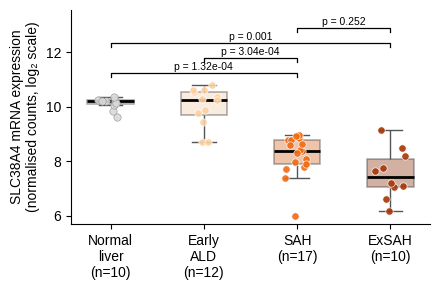

✅ Supplementary Figure 2A saved


In [19]:
# ============================================================
# SUPPLEMENTARY FIGURE 2A
# SLC38A4 expression in individual InTEAM participants
# across the ALD disease spectrum
#
# Input: df_inteam — long-format DataFrame with columns:
#   group_label : str  ("Normal\nliver", "Early\nALD", "SAH", "ExSAH")
#   value       : float (normalised counts, log2 scale)
# Also requires:
#   label_order : list of group_label strings in display order
#   stat_results: list of dicts with keys "group1", "group2", "p_str"
#                 from pairwise Mann-Whitney U tests
# ============================================================

# ── Load individual expression data ──────────────────────────
# Per-sample InTEAM SLC38A4 normalised counts (log2 scale), one row per
# patient biopsy. Source: SLC38A4_expression_InTEAM.csv
# (n = 10 / 12 / 17 / 10 across Normal / Early ALD / SAH / ExSAH,
# matching the InTEAM cohort description in Methods).
df_inteam = pd.read_csv("SLC38A4_expression_InTEAM.csv").rename(
    columns={"stage": "group_label"}
)

label_order = ["Normal\nliver", "Early\nALD", "SAH", "ExSAH"]
stage_to_label = {
    "Normal": "Normal\nliver", "Early ASH": "Early\nALD",
    "SAH": "SAH", "ExSAH": "ExSAH",
}
df_inteam["group_label"] = df_inteam["group_label"].map(stage_to_label)

# Pairwise Mann-Whitney U tests (all 6 combinations), Bonferroni-corrected
import itertools
from scipy.stats import mannwhitneyu

n_comparisons = 6
stat_results = []
for g1, g2 in itertools.combinations(label_order, 2):
    s1 = df_inteam[df_inteam["group_label"] == g1]["value"]
    s2 = df_inteam[df_inteam["group_label"] == g2]["value"]
    _, p = mannwhitneyu(s1, s2, alternative="two-sided")
    p_corr = min(p * n_comparisons, 1.0)
    p_str = (f"p = {p_corr:.3f}" if p_corr >= 0.001
             else f"p = {p_corr:.2e}")
    stat_results.append({"group1": g1, "group2": g2, "p_str": p_str})

palette_inteam = {
    "Normal\nliver": "#d9d9d9",
    "Early\nALD":    "#fdd0a2",
    "SAH":           "#f16913",
    "ExSAH":         "#a63603"
}

fig, ax = plt.subplots(figsize=(4.5, 3))

sns.boxplot(
    data=df_inteam,
    x="group_label", y="value",
    hue="group_label",
    hue_order=label_order,
    order=label_order,
    palette=palette_inteam,
    width=0.5,
    linewidth=1.2,
    fliersize=0,
    legend=False,
    boxprops=dict(alpha=0.4),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="#555555", linewidth=1),
    capprops=dict(color="#555555", linewidth=1),
    ax=ax
)

for i, label in enumerate(label_order):
    sub  = df_inteam[df_inteam["group_label"] == label]
    edge = "#999999" if label == "Normal\nliver" else "white"
    ax.scatter(
        x=np.random.normal(i, 0.08, size=len(sub)),
        y=sub["value"].values,
        color=palette_inteam[label],
        s=28, alpha=0.9,
        edgecolors=edge, linewidths=0.5, zorder=3
    )

def add_significance_bar(ax, x1, x2, y, p_str, bar_height=0.15, fontsize=7.5):
    ax.plot([x1, x1, x2, x2], [y, y + bar_height, y + bar_height, y],
            color="black", linewidth=0.9)
    ax.text((x1 + x2) / 2, y + bar_height + 0.02, p_str,
            ha="center", va="bottom", fontsize=fontsize, color="black")

x_pos   = {label: i for i, label in enumerate(label_order)}
y_max   = df_inteam["value"].max()
bar_gap = 0.55

bar_configs = [
    ("Normal\nliver", "SAH",          y_max + 0.3),
    ("Early\nALD",    "SAH",          y_max + 0.3 + bar_gap),
    ("Normal\nliver", "ExSAH",        y_max + 0.3 + bar_gap * 2),
    ("SAH",           "ExSAH",        y_max + 0.3 + bar_gap * 3),
]

for g1_label, g2_label, y_bar in bar_configs:
    match = [r for r in stat_results
             if r["group1"] == g1_label and r["group2"] == g2_label]
    if match:
        add_significance_bar(ax, x_pos[g1_label], x_pos[g2_label],
                             y_bar, match[0]["p_str"], fontsize=7.5)

n_per_group = df_inteam.groupby("group_label")["value"].count()
ax.set_xticks(range(len(label_order)))
ax.set_xticklabels(
    [f"{lab}\n(n={n_per_group[lab]})" for lab in label_order],
    fontsize=10
)
ax.set_xlabel("", fontsize=10)
ax.set_ylabel("SLC38A4 mRNA expression\n(normalised counts, log\u2082 scale)", fontsize=10)
ax.set_ylim(df_inteam["value"].min() - 0.3,
            y_max + 0.3 + bar_gap * 3 + 0.8)

sns.despine(ax=ax)
plt.tight_layout()

plt.savefig("FigS2A_InTEAM_SLC38A4.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
print("\u2705 Supplementary Figure 2A saved")
